# Causal Effect of Hybrid Powertrain on Fuel Consumption

**Data**: EPA Fuel Economy dataset, ~50k vehicles (raw MY1984-2027; analysis
restricted to MY1998-2026)

**Research question**: What is the causal effect of a hybrid powertrain on **fuel
consumption**, controlling for vehicle characteristics?

**Outcome metric**: gallons per 100 miles (GP100 = 100 / MPG), i.e. how much fuel
a vehicle burns per unit distance. This is the right scale for fuel savings.
MPG is a *reciprocal* of consumption, so differences in MPG systematically
exaggerate savings at the high end ("the MPG illusion"). We report MPG only as a
familiar reference in the naive comparison.

**Identification strategy**: hybrid powertrain is a binary treatment. Confounders
include engine displacement, cylinder count, vehicle class, drive type,
manufacturer, and model year. Because hybrids and gasoline vehicles overlap only
in part of the covariate space, the credible estimand is the effect in the
**overlap (common-support) population**, not a whole-fleet ATE. Matching-based
estimators (PSM, within-model) target the ATT.

**Why this is not trivial**: hybrids are systematically different from gasoline
vehicles - they cluster in specific segments (midsize sedans, compact SUVs), tend
to have smaller displacement, and appear in later model years. A naive mean
comparison conflates the treatment effect with selection into treatment.

**Two corrections relative to a naive pipeline**, worth stating up front:
1. Observations are **not independent** - the EPA file has many trim/drive rows
   per vehicle and the same nameplate recurs across years. We deduplicate exact
   spec rows and use **cluster-robust inference** (clustered by make+base model)
   everywhere, so confidence intervals are honest.
2. Nuisance models for AIPW and the T-learner are **cross-fitted**, so in-sample
   overfitting does not shrink residuals and fake-narrow the intervals.

## 1. Data loading and preparation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import GroupKFold, cross_val_predict
from catboost import CatBoostRegressor, CatBoostClassifier
import warnings

# Narrow suppression: hide only noisy library FutureWarnings, keep everything else
# (we do NOT want to silence leakage / convergence warnings).
warnings.simplefilter('ignore', FutureWarning)

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11
sns.set_style('whitegrid')

GREEN, BLUE, GREY, RED = '#1D9E75', '#378ADD', '#B4B2A9', '#E24B4A'


# CatBoost nuisance factories, used by the propensity model, AIPW, DML and the
# library estimators (fast on the larger sample and consistent across the pipeline).
def cb_reg(seed=42, iters=200):
    return CatBoostRegressor(iterations=iters, depth=5, learning_rate=0.05,
                             verbose=0, random_seed=seed)


def cb_clf(seed=42, iters=200):
    return CatBoostClassifier(iterations=iters, depth=5, learning_rate=0.05,
                              verbose=0, random_seed=seed)

In [2]:
df_raw = pd.read_csv('vehicles.csv', low_memory=False)
print(f"Raw dataset: {df_raw.shape[0]:,} vehicles, {df_raw.shape[1]} columns")
print(f"Year range: {df_raw['year'].min()} - {df_raw['year'].max()}")

Raw dataset: 49,995 vehicles, 84 columns
Year range: 1984 - 2027


## 2. Define treatment and filter data

- **Treatment group**: `atvType == 'Hybrid'` (non-plug-in HEV). Note: on recent
  model years EPA's "Hybrid" flag also covers 48V mild hybrids (e.g. BMW M440i,
  Land Rover MHEV, Ram eTorque) that save far less fuel and dilute the treatment
  (see takeaway 7).
- **Control group**: Pure gasoline vehicles (`atvType` is NaN, gasoline fuel)
- We exclude EVs, PHEVs, diesels, FFVs, CNG, FCVs to keep a clean comparison

In [3]:
# Treatment: hybrid vehicles
hybrid_mask = df_raw['atvType'] == 'Hybrid'

# Control: pure gasoline (not hybrid, not FFV, not diesel, etc.)
gasoline_fuel = df_raw['fuelType1'].isin(
    ['Regular Gasoline', 'Premium Gasoline', 'Midgrade Gasoline'])
# atvType is NaN for most gasoline vehicles but ALSO for diesels and CNG; the
# fuelType1 filter is what actually keeps the control group pure gasoline.
pure_gas_mask = gasoline_fuel & df_raw['atvType'].isna()

# Combine
df = df_raw[hybrid_mask | pure_gas_mask].copy()
df['is_hybrid'] = (df['atvType'] == 'Hybrid').astype(int)

# Hybrids first appear in MY2000; keep 1998+ (pre-2000 gasoline has no hybrid
# counterpart and drops out at the common-support step below). Cap at MY2026: the
# EPA file already lists early-certified MY2027 models, but that year is incomplete.
df = df[(df['year'] >= 1998) & (df['year'] <= 2026)].copy()

print(f"After treatment/fuel filter: {len(df):,} vehicles")
print(f"  Gasoline: {(df['is_hybrid']==0).sum():,}")
print(f"  Hybrid:   {(df['is_hybrid']==1).sum():,}")

After treatment/fuel filter: 29,512 vehicles
  Gasoline: 27,722
  Hybrid:   1,790


## 3. Outcome, confounders, and de-duplication

**Outcome**: `gp100 = 100 / comb08` - gallons per 100 miles (lower is better).

**Confounders (X)**:
- `displ` - engine displacement (liters)
- `cylinders` - number of cylinders
- `year` - model year
- `turbo` - forced induction (turbo/supercharger), binary
- `vclass_simple` - vehicle size class (one-hot)
- `drive_simple` - drive type (one-hot)
- `make` - manufacturer (one-hot)

**Not included as confounders** (mediators / colliders):
- `co2TailpipeGpm` - post-treatment (result of fuel economy)
- Engine power - partially determined by hybrid architecture
- Fuel cost - direct function of MPG

**De-duplication**: the raw file lists a row per trim/drive/transmission. Identical
vehicle specs add no information but would inflate n and shrink CIs. We drop exact
duplicates on the vehicle-defining fields.

In [4]:
# Simplify vehicle class
class_map = {
    'Compact Cars': 'Compact',
    'Subcompact Cars': 'Subcompact',
    'Midsize Cars': 'Midsize',
    'Large Cars': 'Large',
    'Minicompact Cars': 'Minicompact',
    'Two Seaters': 'TwoSeater',
    'Small Station Wagons': 'Wagon',
    'Midsize-Large Station Wagons': 'Wagon',
}
df['vclass_simple'] = df['VClass'].map(class_map).fillna('Other')

# Simplify drive type
drive_map = {
    'Front-Wheel Drive': 'FWD',
    'Rear-Wheel Drive': 'RWD',
    '4-Wheel or All-Wheel Drive': 'AWD',
    'All-Wheel Drive': 'AWD',
    '4-Wheel Drive': 'AWD',
    '2-Wheel Drive': 'FWD',
    'Part-time 4-Wheel Drive': 'AWD'
}
df['drive_simple'] = df['drive'].map(drive_map).fillna('Other')

# Forced induction (turbo/supercharger) as a confounder: turbo prevalence differs by
# group (on recent model years hybrids are actually MORE turbocharged, because EPA's
# "Hybrid" class now includes turbo 48V mild hybrids), and forced induction is an
# alternative efficiency technology that affects fuel use.
df['turbo'] = ((df['tCharger'] == 'T') | (df['sCharger'] == 'S')).astype(int)

num_cov = ['displ', 'cylinders', 'year', 'turbo']
cat_cov = ['vclass_simple', 'drive_simple', 'make']
treatment = 'is_hybrid'

# Outcome in fuel-consumption units
df['gp100'] = 100.0 / df['comb08']
outcome = 'gp100'

# Drop rows with missing covariates / outcome
df = df.dropna(subset=num_cov + cat_cov + ['comb08']).copy()

# De-duplicate exact vehicle specs
key = ['make', 'model', 'year', 'displ', 'cylinders', 'drive', 'VClass',
       'comb08', 'city08', 'highway08', 'co2TailpipeGpm', 'pv4', 'turbo', 'is_hybrid']
n_before = len(df)
df_clean = df.drop_duplicates(subset=key).copy().reset_index(drop=True)
print(f"Dropped {n_before - len(df_clean):,} exact-duplicate spec rows")
print(f"Clean dataset: {len(df_clean):,} vehicles "
      f"({(df_clean.is_hybrid==0).sum():,} gasoline, {(df_clean.is_hybrid==1).sum():,} hybrid)")
YR = f"{int(df_clean['year'].min())}-{int(df_clean['year'].max())}"   # analysis year span, for plot titles

Dropped 748 exact-duplicate spec rows


Clean dataset: 28,764 vehicles (26,991 gasoline, 1,773 hybrid)


In [5]:
# Cluster id for cluster-robust inference: same nameplate across years/trims is not
# an independent observation. Strip trim/drive/hybrid tokens to a base model name.
_TRAIL_TRIMS = {'LE', 'XLE', 'XSE', 'SE', 'SEL', 'LX', 'EX', 'EX-L', 'DX', 'XLS',
                'XLT', 'LTZ', 'LTD', 'Limited', 'PLAT', 'Platinum', 'Touring',
                'Premium', 'Sport', 'Base'}


def base_model_name(model):
    """Nameplate key: strip powertrain/drive/trim tokens so that, e.g.,
    'Camry Hybrid LE' and gasoline 'Camry' map to the same base 'Camry'.
    Handles slash-joined trims like 'Camry LE/SE'."""
    out = str(model)
    for tok in [' Hybrid', ' HEV', ' PHEV', ' 2WD', ' 4WD', ' AWD', ' FWD', ' RWD',
                ' 4-Door', ' 2-Door']:
        out = out.replace(tok, '')
    parts = out.split()
    while len(parts) > 1 and all(t in _TRAIL_TRIMS for t in parts[-1].split('/')):
        parts.pop()
    return ' '.join(parts).strip()


df_clean['base_model'] = df_clean['model'].map(base_model_name)
df_clean['cluster_key'] = df_clean['make'] + '||' + df_clean['base_model']
cluster_id = pd.factorize(df_clean['cluster_key'])[0]
print(f"Clusters (make + base model): {df_clean['cluster_key'].nunique():,} "
      f"for {len(df_clean):,} rows")

Clusters (make + base model): 2,727 for 28,764 rows


In [6]:
# One-hot design matrix (fixes ordinal-encoding-as-numeric bug). Used by every
# model so categoricals are never treated as ordered numbers.
Xd_df = pd.concat(
    [df_clean[num_cov].astype(float),
     pd.get_dummies(df_clean[cat_cov], drop_first=True).astype(float)],
    axis=1,
)
Xd = Xd_df.values
feat_names = list(Xd_df.columns)

T = df_clean[treatment].values.astype(int)
Y = df_clean[outcome].values.astype(float)
mpg = df_clean['comb08'].values.astype(float)
print(f"Design matrix: {Xd.shape[1]} features "
      f"({len(num_cov)} numeric + {Xd.shape[1]-len(num_cov)} one-hot)")

Design matrix: 86 features (4 numeric + 82 one-hot)


## 4. Covariate balance check (pre-matching)

If confounders were balanced between treatment and control, a simple t-test would
do. We compute standardized mean differences (SMD) on the design columns.

In [7]:
def smd(treated, control):
    """Standardized Mean Difference"""
    sd = np.sqrt((treated.var() + control.var()) / 2)
    return (treated.mean() - control.mean()) / sd if sd > 0 else 0.0


print("Standardized Mean Differences (pre-matching):")
print("  |SMD| > 0.1 indicates meaningful imbalance\n")
print("  Numeric confounders:")
for col in num_cov:
    s = smd(Xd_df.loc[T == 1, col], Xd_df.loc[T == 0, col])
    flag = " *** IMBALANCED" if abs(s) > 0.1 else ""
    print(f"    {col:22s}: SMD = {s:+.3f}{flag}")

# Largest categorical imbalances
cat_smds = []
for col in feat_names[len(num_cov):]:
    cat_smds.append((col, smd(Xd_df.loc[T == 1, col], Xd_df.loc[T == 0, col])))
cat_smds.sort(key=lambda kv: -abs(kv[1]))
print("\n  Largest one-hot imbalances:")
for col, s in cat_smds[:8]:
    print(f"    {col:22s}: SMD = {s:+.3f}")

Standardized Mean Differences (pre-matching):
  |SMD| > 0.1 indicates meaningful imbalance

  Numeric confounders:
    displ                 : SMD = -0.365 *** IMBALANCED
    cylinders             : SMD = -0.316 *** IMBALANCED
    year                  : SMD = +1.161 *** IMBALANCED
    turbo                 : SMD = +0.262 *** IMBALANCED

  Largest one-hot imbalances:
    drive_simple_RWD      : SMD = -0.452
    make_Toyota           : SMD = +0.353
    make_Mercedes-Benz    : SMD = +0.319
    vclass_simple_Minicompact: SMD = -0.303
    make_Porsche          : SMD = -0.281
    make_Lexus            : SMD = +0.278
    make_Land Rover       : SMD = +0.276
    make_Dodge            : SMD = -0.260


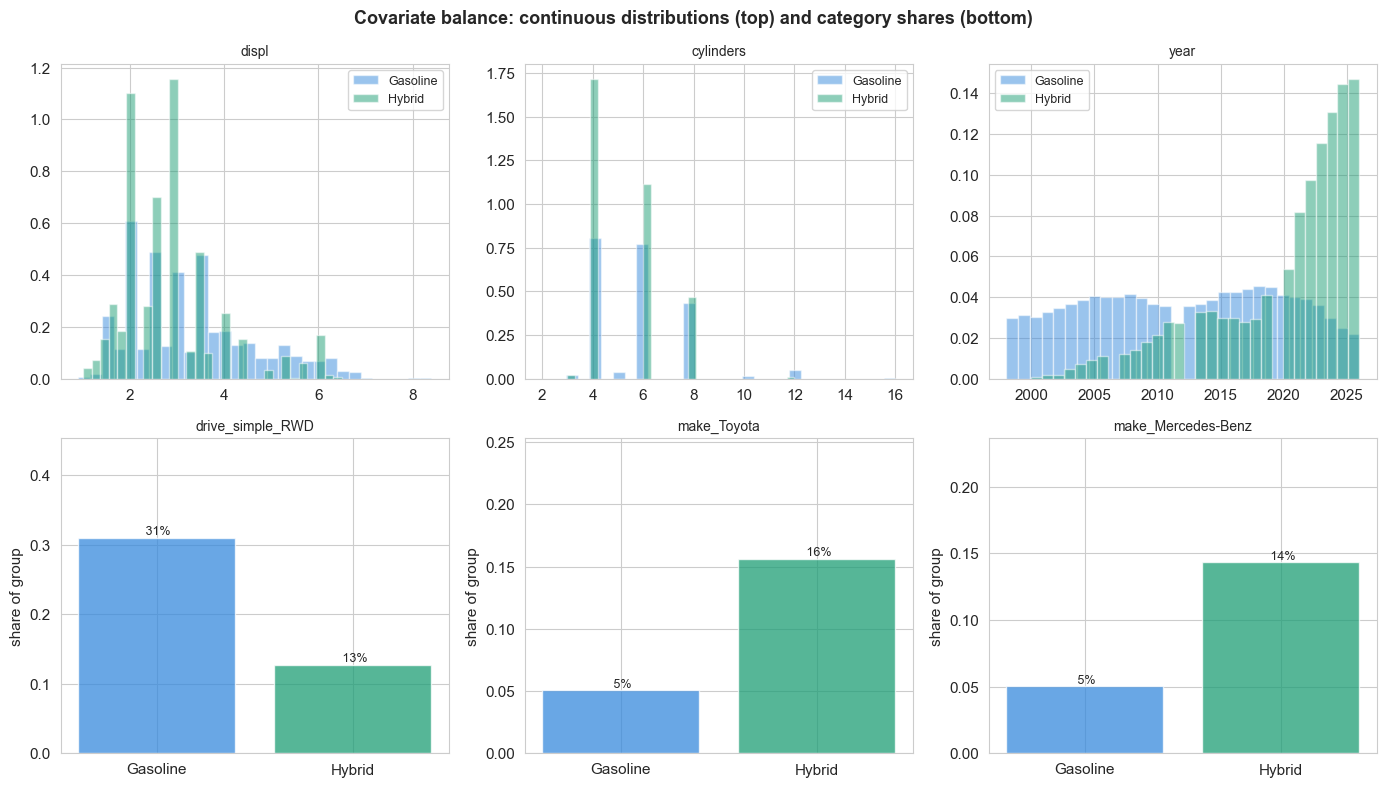

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
# Top row: continuous confounders as density histograms
for ax, col in zip(axes[0], num_cov):
    for grp, label, color in [(0, 'Gasoline', BLUE), (1, 'Hybrid', GREEN)]:
        ax.hist(Xd_df.loc[T == grp, col], bins=30, alpha=0.5, label=label,
                color=color, density=True)
    ax.set_title(col, fontsize=10)
    ax.legend(fontsize=9)
# Bottom row: most-imbalanced categories as group shares (binary dummies are
# unreadable as histograms - a share bar answers "how common in each group?")
for ax, (col, _) in zip(axes[1], cat_smds[:3]):
    shares = [Xd_df.loc[T == 0, col].mean(), Xd_df.loc[T == 1, col].mean()]
    ax.bar(['Gasoline', 'Hybrid'], shares, color=[BLUE, GREEN], alpha=0.75, edgecolor='white')
    ax.set_ylim(0, min(1, max(shares) * 1.3 + 0.05))
    ax.set_title(col, fontsize=10)
    ax.set_ylabel('share of group')
    for j, v in enumerate(shares):
        ax.text(j, v, f' {v:.0%}', ha='center', va='bottom', fontsize=9)
plt.suptitle('Covariate balance: continuous distributions (top) and category shares (bottom)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('01_covariate_balance.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Naive comparison and the MPG illusion

This is what you get without any causal reasoning - just compare group means.
We show it both in MPG (familiar, but misleading) and in gallons/100mi (correct).

In [9]:
gp_gas, gp_hyb = Y[T == 0], Y[T == 1]
mpg_gas, mpg_hyb = mpg[T == 0], mpg[T == 1]

naive_ate = gp_hyb.mean() - gp_gas.mean()          # gal/100mi, negative = saves fuel
naive_pct = naive_ate / gp_gas.mean() * 100
naive_mpg = mpg_hyb.mean() - mpg_gas.mean()

print("Naive comparison (no adjustment):")
print(f"  Mean MPG:      Gasoline {mpg_gas.mean():.1f}  vs  Hybrid {mpg_hyb.mean():.1f}"
      f"   -> +{naive_mpg:.1f} MPG (+{naive_mpg/mpg_gas.mean()*100:.0f}%)   <- the 'MPG illusion'")
print(f"  Mean gal/100mi: Gasoline {gp_gas.mean():.2f} vs  Hybrid {gp_hyb.mean():.2f}"
      f"   -> {naive_ate:+.2f} ({naive_pct:+.0f}% fuel)")
print(f"\n  The MPG framing (+{naive_mpg/mpg_gas.mean()*100:.0f}%) overstates the true "
      f"fuel saving ({naive_pct:+.0f}%).")
print("  Both are still BIASED: hybrids are midsize sedans, not pickups/SUVs.")

Naive comparison (no adjustment):
  Mean MPG:      Gasoline 20.9  vs  Hybrid 29.7   -> +8.8 MPG (+42%)   <- the 'MPG illusion'
  Mean gal/100mi: Gasoline 5.04 vs  Hybrid 3.75   -> -1.29 (-26% fuel)

  The MPG framing (+42%) overstates the true fuel saving (-26%).
  Both are still BIASED: hybrids are midsize sedans, not pickups/SUVs.


## 6. Propensity score and the overlap (common-support) sample

P(hybrid | X). We need good overlap (positivity). Because gasoline vehicles that
look nothing like any hybrid (big pickups) carry no counterfactual information,
we restrict all adjusted estimators to the **common-support / overlap** sample.
The resulting estimand is the average effect in the overlap (common-support)
population - not a whole-fleet ATE (not identified here). Matching-based rows
(PSM, Mahalanobis, within-model) target the ATT; weighting/regression rows
(OLS, IPW, AIPW, DML, IRM, forest) target the overlap-sample ATE.

The score is **cross-fitted** (out-of-fold, grouped by nameplate) so it is not
overfit in-sample - the same reason we cross-fit the AIPW/DML nuisances.

In [10]:
ps = cross_val_predict(
    cb_clf(), Xd, T, groups=cluster_id,
    cv=GroupKFold(n_splits=5, shuffle=True, random_state=42),
    method='predict_proba')[:, 1]
df_clean['ps'] = ps

print("Propensity score (cross-fitted GBM) distribution:")
print(f"  Gasoline: mean={ps[T==0].mean():.4f}, median={np.median(ps[T==0]):.4f}")
print(f"  Hybrid:   mean={ps[T==1].mean():.4f}, median={np.median(ps[T==1]):.4f}")

# Common support (overlap)
ps_min = max(ps[T == 1].min(), ps[T == 0].min())
ps_max = min(ps[T == 1].max(), ps[T == 0].max())
ov = (ps >= ps_min) & (ps <= ps_max)
print(f"\nCommon support: {ov.sum():,} / {len(ps):,} vehicles retained "
      f"({(T[ov]==1).sum():,} hybrid, {(T[ov]==0).sum():,} gasoline)")

# Overlap-sample arrays reused by the adjusted estimators
Xd_ov = Xd[ov]
T_ov = T[ov]
Y_ov = Y[ov]
ps_ov = ps[ov]
clu_ov = cluster_id[ov]
gas_base_ov = Y_ov[T_ov == 0].mean()   # baseline fuel use for % reduction

Propensity score (cross-fitted GBM) distribution:
  Gasoline: mean=0.0415, median=0.0145
  Hybrid:   mean=0.3247, median=0.2808

Common support: 26,206 / 28,764 vehicles retained (1,763 hybrid, 24,443 gasoline)


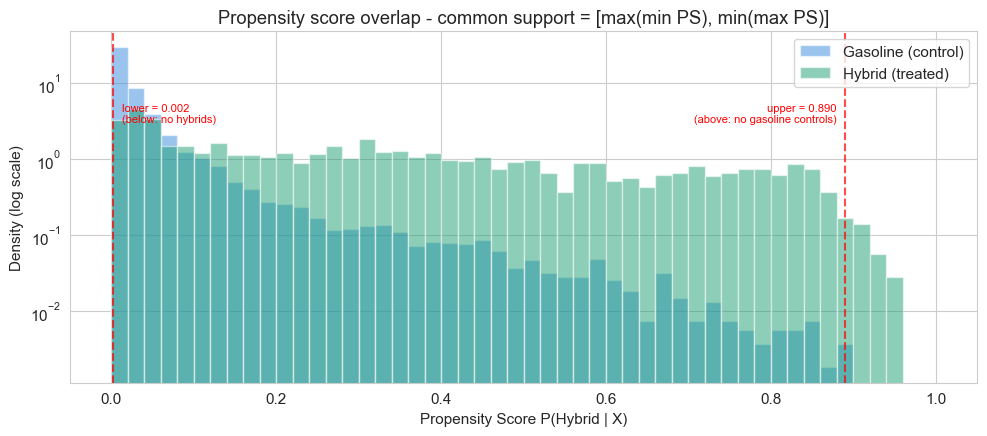

In [11]:
fig, ax = plt.subplots(figsize=(10, 4.5))
bins = np.linspace(0, 1, 51)
ax.hist(ps[T == 0], bins=bins, alpha=0.5, label='Gasoline (control)', color=BLUE, density=True)
ax.hist(ps[T == 1], bins=bins, alpha=0.5, label='Hybrid (treated)', color=GREEN, density=True)
# Log y-scale: on a linear axis the huge gasoline spike at PS~0 dwarfs everything and
# hides the sparse hybrid mass, making the support bounds look arbitrary.
ax.set_yscale('log')
ax.axvline(ps_min, color='red', linestyle='--', alpha=0.7)
ax.axvline(ps_max, color='red', linestyle='--', alpha=0.7)
ytxt = ax.get_ylim()[1] * 0.06
ax.text(ps_min + 0.01, ytxt, f'lower = {ps_min:.3f}\n(below: no hybrids)',
        fontsize=8, color='red', va='bottom', ha='left')
ax.text(ps_max - 0.01, ytxt, f'upper = {ps_max:.3f}\n(above: no gasoline controls)',
        fontsize=8, color='red', va='bottom', ha='right')
ax.set_xlabel('Propensity Score P(Hybrid | X)')
ax.set_ylabel('Density (log scale)')
ax.set_title('Propensity score overlap - common support = [max(min PS), min(max PS)]')
ax.legend(loc='upper right')
plt.tight_layout()
plt.savefig('02_propensity_overlap.png', dpi=150, bbox_inches='tight')
plt.show()

In [12]:
# Cluster bootstrap helper: resample clusters (not rows) so non-independent
# trim/year replicates do not fake precision.
def cluster_boot_ci(clu, stat_fn, n_boot=1000, seed=42, alpha=0.05):
    rng = np.random.RandomState(seed)
    uniq = np.unique(clu)
    idx_by = {c: np.where(clu == c)[0] for c in uniq}
    ests = []
    for _ in range(n_boot):
        drawn = rng.choice(uniq, size=len(uniq), replace=True)
        rows = np.concatenate([idx_by[c] for c in drawn])
        v = stat_fn(rows)
        if v is not None and np.isfinite(v):
            ests.append(v)
    lo, hi = np.percentile(ests, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return lo, hi, np.std(ests)

## 7. OLS regression adjustment (overlap sample, one-hot, clustered SE)

Regress Y on T and one-hot X on the overlap sample. Categoricals enter as dummies
(not as a meaningless ordinal number). Standard errors are clustered by nameplate.

In [13]:
import statsmodels.api as sm

X_ols = sm.add_constant(np.column_stack([T_ov.astype(float), Xd_ov]))
ols = sm.OLS(Y_ov, X_ols).fit(cov_type='cluster', cov_kwds={'groups': clu_ov})
ate_ols = ols.params[1]
ci_ols = ols.conf_int()[1]
print("OLS regression adjustment (overlap, cluster-robust SE):")
print(f"  ATE: {ate_ols:+.3f} gal/100mi ({ate_ols/gas_base_ov*100:+.1f}% fuel)")
print(f"  95% CI: [{ci_ols[0]:.3f}, {ci_ols[1]:.3f}]   p = {ols.pvalues[1]:.2e}")

OLS regression adjustment (overlap, cluster-robust SE):
  ATE: -0.726 gal/100mi (-14.5% fuel)
  95% CI: [-0.813, -0.640]   p = 1.82e-60


## 8. Propensity Score Matching (PSM) -> ATT

For each hybrid, find the nearest gasoline vehicle by propensity score (on the
overlap sample). Compare outcomes within matched pairs. CI via cluster bootstrap
over treated nameplates.

In [14]:
def psm_att(rows):
    """1:1 NN PS matching (with replacement) on a set of overlap rows -> ATT.
    Re-matches on every call so the bootstrap captures matching variance and
    both-arm sampling variance. The bootstrap is only approximate for 1:1 NN matching
    with replacement (Abadie & Imbens 2008 show it lacks a general consistency
    guarantee); we report it as an approximate CI."""
    t, y, p = T_ov[rows], Y_ov[rows], ps_ov[rows]
    it_, ic_ = np.where(t == 1)[0], np.where(t == 0)[0]
    if len(it_) == 0 or len(ic_) == 0:
        return None
    _, ix = NearestNeighbors(n_neighbors=1).fit(p[ic_].reshape(-1, 1)).kneighbors(
        p[it_].reshape(-1, 1))
    return y[it_].mean() - y[ic_[ix.ravel()]].mean()


ate_psm = psm_att(np.arange(len(Y_ov)))
ci_psm = cluster_boot_ci(clu_ov, psm_att)[:2]   # both arms resampled by nameplate, re-matched

# Full-sample match, for the balance diagnostic only
it0, ic0 = np.where(T_ov == 1)[0], np.where(T_ov == 0)[0]
_, ix0 = NearestNeighbors(n_neighbors=1).fit(ps_ov[ic0].reshape(-1, 1)).kneighbors(
    ps_ov[it0].reshape(-1, 1))
matched0 = ic0[ix0.ravel()]

print("Propensity Score Matching (1:1 NN, ATT of overlap-treated):")
print(f"  Treated matched: {len(it0)}")
print(f"  ATE: {ate_psm:+.3f} gal/100mi ({ate_psm/gas_base_ov*100:+.1f}% fuel)")
print(f"  95% cluster-bootstrap CI (re-matched, both arms): [{ci_psm[0]:.3f}, {ci_psm[1]:.3f}]")
print(f"  PS balance: treated {ps_ov[it0].mean():.4f} vs matched {ps_ov[matched0].mean():.4f}")

Propensity Score Matching (1:1 NN, ATT of overlap-treated):
  Treated matched: 1763
  ATE: -0.779 gal/100mi (-15.6% fuel)
  95% cluster-bootstrap CI (re-matched, both arms): [-1.004, -0.602]
  PS balance: treated 0.3214 vs matched 0.3213


## 9. Inverse Probability Weighting (IPW, Hajek normalized)

Weight each observation by the inverse of its propensity score, on the overlap
sample. We report the Hajek (self-normalized) estimator; CI via cluster bootstrap.

In [15]:
eps = 0.01


def hajek_ate(rows):
    t, y, p = T_ov[rows], Y_ov[rows], np.clip(ps_ov[rows], eps, 1 - eps)
    w1, w0 = t / p, (1 - t) / (1 - p)
    if w1.sum() == 0 or w0.sum() == 0:
        return None
    return (w1 * y).sum() / w1.sum() - (w0 * y).sum() / w0.sum()


ate_ipw = hajek_ate(np.arange(len(Y_ov)))
ci_ipw = cluster_boot_ci(clu_ov, hajek_ate)[:2]
print("Inverse Probability Weighting (Hajek, overlap):")
print(f"  ATE: {ate_ipw:+.3f} gal/100mi ({ate_ipw/gas_base_ov*100:+.1f}% fuel)")
print(f"  95% cluster-bootstrap CI: [{ci_ipw[0]:.3f}, {ci_ipw[1]:.3f}]")

Inverse Probability Weighting (Hajek, overlap):
  ATE: -0.866 gal/100mi (-17.3% fuel)
  95% cluster-bootstrap CI: [-1.185, -0.544]


## 10. Augmented IPW (Doubly Robust / AIPW) - cross-fitted

Combines outcome regression and propensity weighting; consistent if **either**
model is correct. Nuisances are **cross-fitted with GroupKFold (grouped by
nameplate)** so in-sample overfitting does not shrink residuals and replicate
trims do not leak across folds. CI is the cluster-robust influence-function
interval (cluster sums of *centered* scores).

In [16]:
def crossfit_aipw(X, T, Y, clu, n_splits=5, seed=42):
    n = len(Y)
    mu1 = np.zeros(n)
    mu0 = np.zeros(n)
    psx = np.zeros(n)
    gkf = GroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    for tr, te in gkf.split(X, groups=clu):
        m1 = cb_reg(seed).fit(X[tr][T[tr] == 1], Y[tr][T[tr] == 1])
        m0 = cb_reg(seed).fit(X[tr][T[tr] == 0], Y[tr][T[tr] == 0])
        pm = cb_clf(seed).fit(X[tr], T[tr])
        mu1[te] = m1.predict(X[te])
        mu0[te] = m0.predict(X[te])
        psx[te] = pm.predict_proba(X[te])[:, 1]
    psx = np.clip(psx, eps, 1 - eps)
    # Per-unit AIPW score (influence function)
    score = (T * (Y - mu1) / psx + mu1) - ((1 - T) * (Y - mu0) / (1 - psx) + mu0)
    ate = score.mean()
    # Cluster-robust SE of a mean: cluster sums of CENTERED influence scores
    # (score - ate); without centering the raw sum carries a spurious ate^2 term.
    cluster_sums = np.array([(score[clu == c] - ate).sum() for c in np.unique(clu)])
    se = np.sqrt((cluster_sums ** 2).sum()) / len(score)
    return ate, se, score


ate_aipw, se_aipw, _ = crossfit_aipw(Xd_ov, T_ov, Y_ov, clu_ov)
ci_aipw = (ate_aipw - 1.96 * se_aipw, ate_aipw + 1.96 * se_aipw)
print("Augmented IPW (Doubly Robust, cross-fitted, cluster-robust SE):")
print(f"  ATE: {ate_aipw:+.3f} gal/100mi ({ate_aipw/gas_base_ov*100:+.1f}% fuel)")
print(f"  SE: {se_aipw:.3f}   95% CI: [{ci_aipw[0]:.3f}, {ci_aipw[1]:.3f}]")

Augmented IPW (Doubly Robust, cross-fitted, cluster-robust SE):
  ATE: -0.896 gal/100mi (-17.9% fuel)
  SE: 0.052   95% CI: [-0.998, -0.795]


## 11. Double Machine Learning (DML) with CatBoost

Chernozhukov et al. (2018): partial out confounders from both T and Y using
flexible ML, then regress residuals on residuals. Cross-fitting uses GroupKFold
(grouped by nameplate) to prevent overfitting and cross-fold leakage; SE is
cluster-robust.

In [17]:
def dml_estimate(X, T, Y, clu, n_splits=5, random_state=42):
    gkf = GroupKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    rY = np.zeros(len(Y))
    rT = np.zeros(len(T))
    for tr, te in gkf.split(X, groups=clu):
        m_y = CatBoostRegressor(iterations=300, depth=5, learning_rate=0.05,
                                verbose=0, random_seed=random_state)
        m_y.fit(X[tr], Y[tr])
        rY[te] = Y[te] - m_y.predict(X[te])
        m_t = CatBoostRegressor(iterations=300, depth=5, learning_rate=0.05,
                                verbose=0, random_seed=random_state)
        m_t.fit(X[tr], T[tr])
        rT[te] = T[te] - m_t.predict(X[te])
    B = np.sum(rT ** 2)
    theta = np.sum(rT * rY) / B
    g = rT * (rY - theta * rT)                       # influence contributions
    cluster_sums = np.array([g[clu == c].sum() for c in np.unique(clu)])
    se = np.sqrt((cluster_sums ** 2).sum()) / B      # cluster-robust
    return theta, se


ate_dml, se_dml = dml_estimate(Xd_ov, T_ov.astype(float), Y_ov, clu_ov)
ci_dml = (ate_dml - 1.96 * se_dml, ate_dml + 1.96 * se_dml)
dml_seeds = [dml_estimate(Xd_ov, T_ov.astype(float), Y_ov, clu_ov, random_state=s)[0]
             for s in [42, 123, 456]]
print("Double Machine Learning (CatBoost, 5-fold cross-fitting, cluster-robust SE):")
print(f"  ATE: {ate_dml:+.3f} gal/100mi ({ate_dml/gas_base_ov*100:+.1f}% fuel)")
print(f"  SE: {se_dml:.3f}   95% CI: [{ci_dml[0]:.3f}, {ci_dml[1]:.3f}]")
print(f"  Stability across seeds: {np.mean(dml_seeds):.3f} +/- {np.std(dml_seeds):.3f}")

Double Machine Learning (CatBoost, 5-fold cross-fitting, cluster-robust SE):
  ATE: -0.853 gal/100mi (-17.1% fuel)
  SE: 0.038   95% CI: [-0.928, -0.778]
  Stability across seeds: -0.851 +/- 0.003


### Estimand sensitivity: is engine size a confounder or part of the package?

Displacement, cylinders and forced induction are controlled as confounders, but
engine downsizing / turbocharging are partly *alternatives* to hybridization.
Keeping them isolates the effect **holding engine tech fixed** (the main estimate);
dropping all three gives the **total hybrid-package effect** (larger). We report
both so the estimand is explicit rather than implicit.

In [18]:
keep_pkg = [i for i, nm in enumerate(feat_names) if nm not in ('displ', 'cylinders', 'turbo')]
ate_pkg, se_pkg = dml_estimate(Xd_ov[:, keep_pkg], T_ov.astype(float), Y_ov, clu_ov)
print("Estimand sensitivity (DML):")
print(f"  Holding engine size + induction fixed (main):      {ate_dml:+.3f} gal/100mi")
print(f"  Total package effect (drop displ/cylinders/turbo): {ate_pkg:+.3f} gal/100mi (SE {se_pkg:.3f})")

Estimand sensitivity (DML):
  Holding engine size + induction fixed (main):      -0.853 gal/100mi
  Total package effect (drop displ/cylinders/turbo): -1.007 gal/100mi (SE 0.057)


## 12. Within-model exact matching (strongest design)

Compare the **same model** in gasoline and hybrid versions (e.g., Toyota Camry vs
Camry Hybrid). Same chassis, class, manufacturer - almost a natural experiment.
We require identical base nameplate AND drive type, and pick the closest gasoline
twin by displacement with a deterministic tie-break. CI via cluster bootstrap over
nameplates. This is stricter (fewer, cleaner pairs) than a substring match.

In [19]:
hybrid_df = df_clean[df_clean['is_hybrid'] == 1].copy()
gas_df = df_clean[df_clean['is_hybrid'] == 0].copy()

pairs = []
for _, row in hybrid_df.iterrows():
    # Require the SAME base nameplate and drive type (not a substring match, which
    # mispaired e.g. Camry Hybrid -> Camry Solara, Civic Hybrid -> Civic HX).
    gm = gas_df[
        (gas_df['make'] == row['make']) &
        (gas_df['base_model'] == row['base_model']) &
        (gas_df['drive_simple'] == row['drive_simple']) &
        (gas_df['year'].between(row['year'] - 1, row['year'] + 1))
    ].copy()
    if len(gm) > 0:
        gm['displ_diff'] = (gm['displ'] - row['displ']).abs()
        gm['turbo_diff'] = (gm['turbo'] != row['turbo']).astype(int)
        gm['year_diff'] = (gm['year'] - row['year']).abs()
        # Prefer the same forced-induction status, then closest displacement, then a
        # deterministic tie-break - so a NA hybrid is not matched to a turbo/perf trim
        # (e.g. Civic Hybrid vs Civic Type R) that merely ties on displacement.
        best = gm.sort_values(['turbo_diff', 'displ_diff', 'year_diff', 'model', 'year']).iloc[0]
        pairs.append({
            'cluster_key': row['cluster_key'],
            'make': row['make'], 'model_hybrid': row['model'],
            'model_gas': best['model'], 'year': row['year'],
            'mpg_hybrid': row['comb08'], 'mpg_gas': best['comb08'],
            'gp_hybrid': 100.0 / row['comb08'], 'gp_gas': 100.0 / best['comb08'],
            'gpc_hybrid': 100.0 / row['city08'], 'gpc_gas': 100.0 / best['city08'],
            'gph_hybrid': 100.0 / row['highway08'], 'gph_gas': 100.0 / best['highway08'],
        })

pairs_df = pd.DataFrame(pairs)
pairs_df['gp_diff'] = pairs_df['gp_hybrid'] - pairs_df['gp_gas']       # <0 = saves fuel
pairs_df['gp_pct'] = pairs_df['gp_diff'] / pairs_df['gp_gas'] * 100
pairs_df['city_diff'] = pairs_df['gpc_hybrid'] - pairs_df['gpc_gas']
pairs_df['hwy_diff'] = pairs_df['gph_hybrid'] - pairs_df['gph_gas']
pairs_df['mpg_diff'] = pairs_df['mpg_hybrid'] - pairs_df['mpg_gas']

ate_within = pairs_df['gp_diff'].mean()
ci_within = cluster_boot_ci(
    pd.factorize(pairs_df['cluster_key'])[0],
    lambda rows: pairs_df['gp_diff'].values[rows].mean(),
)[:2]

print(f"Exact matched pairs: {len(pairs_df)}  "
      f"({pairs_df['cluster_key'].nunique()} distinct nameplates)")
print("Within-model effect on fuel consumption:")
print(f"  Combined: {ate_within:+.3f} gal/100mi ({pairs_df['gp_pct'].mean():+.1f}% fuel)")
print(f"  City:     {pairs_df['city_diff'].mean():+.3f} gal/100mi")
print(f"  Highway:  {pairs_df['hwy_diff'].mean():+.3f} gal/100mi")
print(f"  (MPG reference: {pairs_df['mpg_diff'].mean():+.1f} MPG)")
print(f"  95% cluster-bootstrap CI: [{ci_within[0]:.3f}, {ci_within[1]:.3f}]")

Exact matched pairs: 611  (142 distinct nameplates)
Within-model effect on fuel consumption:
  Combined: -0.944 gal/100mi (-22.9% fuel)
  City:     -1.382 gal/100mi
  Highway:  -0.402 gal/100mi
  (MPG reference: +8.3 MPG)
  95% cluster-bootstrap CI: [-1.051, -0.831]


In [20]:
print("\nTop matched pairs (largest fuel saving):\n")
top = (pairs_df.assign(saving=-pairs_df['gp_diff'])
       .nlargest(15, 'saving')[['make', 'model_hybrid', 'year', 'mpg_gas',
                                 'mpg_hybrid', 'gp_diff', 'gp_pct']])
print(top.to_string(index=False))


Top matched pairs (largest fuel saving):

    make          model_hybrid  year  mpg_gas  mpg_hybrid   gp_diff     gp_pct
     Ram              1500 4WD  2026       12          18 -2.777778 -33.333333
     GMC Yukon 1500 Hybrid 2WD  2008       14          21 -2.380952 -33.333333
     GMC Yukon 1500 Hybrid 2WD  2009       14          21 -2.380952 -33.333333
 Lincoln        MKZ Hybrid FWD  2015       21          40 -2.261905 -47.500000
 Lincoln        MKZ Hybrid FWD  2016       21          40 -2.261905 -47.500000
 Lincoln        MKZ Hybrid FWD  2017       21          40 -2.261905 -47.500000
Cadillac   Escalade Hybrid 2WD  2009       14          20 -2.142857 -30.000000
  Toyota           Sequoia 4WD  2023       14          20 -2.142857 -30.000000
  Toyota     Sienna Hybrid AWD  2021       20          35 -2.142857 -42.857143
 Lincoln        MKZ Hybrid FWD  2011       21          38 -2.130326 -44.736842
 Lincoln        MKZ Hybrid FWD  2012       21          38 -2.130326 -44.736842
 Lincoln 

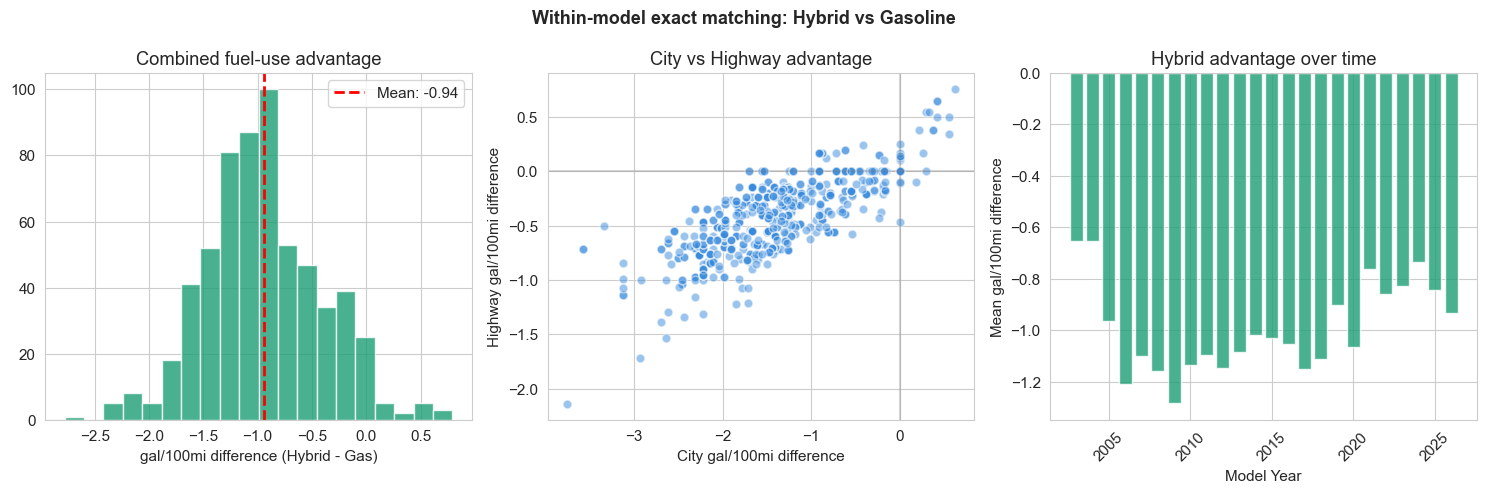

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].hist(pairs_df['gp_diff'], bins=20, color=GREEN, edgecolor='white', alpha=0.8)
axes[0].axvline(ate_within, color='red', linestyle='--', linewidth=2,
                label=f'Mean: {ate_within:+.2f}')
axes[0].set_xlabel('gal/100mi difference (Hybrid - Gas)')
axes[0].set_title('Combined fuel-use advantage')
axes[0].legend()

axes[1].scatter(pairs_df['city_diff'], pairs_df['hwy_diff'],
                alpha=0.5, c=BLUE, edgecolor='white', s=40)
axes[1].axhline(0, color='gray', alpha=0.3)
axes[1].axvline(0, color='gray', alpha=0.3)
axes[1].set_xlabel('City gal/100mi difference')
axes[1].set_ylabel('Highway gal/100mi difference')
axes[1].set_title('City vs Highway advantage')

yearly = pairs_df.groupby('year')['gp_diff'].mean()
axes[2].bar(yearly.index, yearly.values, color=GREEN, edgecolor='white', alpha=0.8)
axes[2].set_xlabel('Model Year')
axes[2].set_ylabel('Mean gal/100mi difference')
axes[2].set_title('Hybrid advantage over time')
axes[2].tick_params(axis='x', rotation=45)

plt.suptitle('Within-model exact matching: Hybrid vs Gasoline', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('03_exact_matching.png', dpi=150, bbox_inches='tight')
plt.show()

## 13. Heterogeneous Treatment Effects (CATE) - cross-fitted T-learner

Does the effect vary by class or engine size? Cross-fitted T-learner (separate
CatBoost models for treated/control, out-of-fold GroupKFold predictions) avoids
in-sample optimism. Estimated on the **overlap sample**, and we report only
classes/bins with real hybrid support (no off-support extrapolation, e.g. 6L+
trucks have zero hybrids). CATE < 0 means the hybrid burns less fuel.

In [22]:
MIN_TREATED = 15   # only report subgroups with at least this many hybrids


def crossfit_tlearner(X, T, Y, groups, n_splits=5, seed=42):
    cate = np.zeros(len(Y))
    gkf = GroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    for tr, te in gkf.split(X, groups=groups):
        m1 = CatBoostRegressor(iterations=400, depth=5, learning_rate=0.05,
                               verbose=0, random_seed=seed)
        m0 = CatBoostRegressor(iterations=400, depth=5, learning_rate=0.05,
                               verbose=0, random_seed=seed)
        m1.fit(X[tr][T[tr] == 1], Y[tr][T[tr] == 1])
        m0.fit(X[tr][T[tr] == 0], Y[tr][T[tr] == 0])
        cate[te] = m1.predict(X[te]) - m0.predict(X[te])
    return cate


cate_ov = crossfit_tlearner(Xd_ov, T_ov, Y_ov, clu_ov)
cate_df = df_clean.loc[ov].reset_index(drop=True).copy()
cate_df['cate'] = cate_ov

print("CATE by vehicle class (gal/100mi, negative = saves fuel; overlap sample):")
for cls in sorted(cate_df['vclass_simple'].unique()):
    m = cate_df['vclass_simple'] == cls
    n_tr = int((m & (cate_df['is_hybrid'] == 1)).sum())
    if m.sum() > 20 and n_tr >= MIN_TREATED:
        print(f"  {cls:15s}: CATE = {cate_df.loc[m,'cate'].mean():+.2f}  "
              f"(n={m.sum():,}, hybrids={n_tr})")

CATE by vehicle class (gal/100mi, negative = saves fuel; overlap sample):
  Compact        : CATE = -0.84  (n=3,372, hybrids=201)
  Large          : CATE = -0.77  (n=1,641, hybrids=106)
  Midsize        : CATE = -0.84  (n=3,548, hybrids=374)
  Other          : CATE = -1.08  (n=12,266, hybrids=902)
  Subcompact     : CATE = -0.71  (n=2,101, hybrids=95)
  TwoSeater      : CATE = -0.37  (n=1,505, hybrids=45)
  Wagon          : CATE = -0.88  (n=833, hybrids=38)


In [23]:
cate_df['displ_bin'] = pd.cut(cate_df['displ'], bins=[0, 2, 3, 4, 6, 10],
                              labels=['<2L', '2-3L', '3-4L', '4-6L', '6L+'])
print("\nCATE by engine displacement (overlap sample, hybrid-supported bins):")
for b in ['<2L', '2-3L', '3-4L', '4-6L', '6L+']:
    m = cate_df['displ_bin'] == b
    n_tr = int((m & (cate_df['is_hybrid'] == 1)).sum())
    if m.sum() > 10 and n_tr >= MIN_TREATED:
        print(f"  {b:8s}: CATE = {cate_df.loc[m,'cate'].mean():+.2f}  "
              f"(n={m.sum():,}, hybrids={n_tr})")


CATE by engine displacement (overlap sample, hybrid-supported bins):
  <2L     : CATE = -0.70  (n=6,901, hybrids=598)
  2-3L    : CATE = -0.96  (n=7,464, hybrids=685)
  3-4L    : CATE = -0.88  (n=6,192, hybrids=308)
  4-6L    : CATE = -1.01  (n=4,713, hybrids=165)


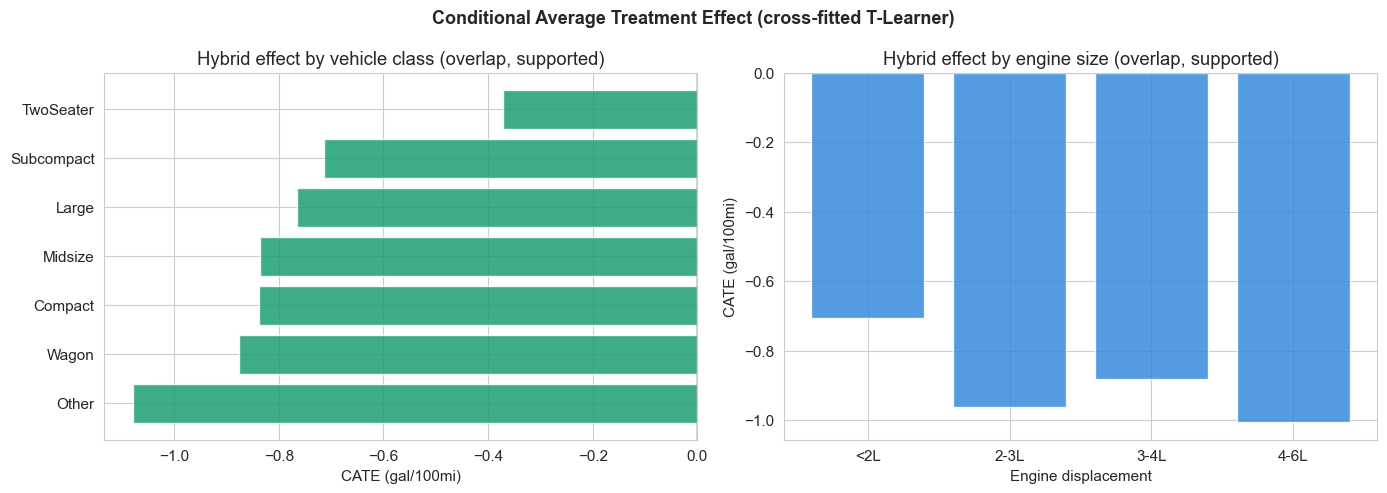

In [24]:
hyb_by_cls = cate_df[cate_df['is_hybrid'] == 1].groupby('vclass_simple').size()
hyb_by_disp = cate_df[cate_df['is_hybrid'] == 1].groupby('displ_bin', observed=True).size()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cate_cls = cate_df.groupby('vclass_simple')['cate'].agg(['mean', 'count'])
cate_cls['hyb'] = hyb_by_cls.reindex(cate_cls.index).fillna(0)
cate_cls = cate_cls[(cate_cls['count'] > 20) & (cate_cls['hyb'] >= MIN_TREATED)].sort_values('mean')
axes[0].barh(cate_cls.index, cate_cls['mean'], color=GREEN, edgecolor='white', alpha=0.85)
axes[0].set_xlabel('CATE (gal/100mi)')
axes[0].set_title('Hybrid effect by vehicle class (overlap, supported)')
axes[0].axvline(0, color='gray', alpha=0.3)

cate_disp = cate_df.groupby('displ_bin', observed=True)['cate'].agg(['mean', 'count'])
cate_disp['hyb'] = hyb_by_disp.reindex(cate_disp.index).fillna(0)
cate_disp = cate_disp[(cate_disp['count'] > 10) & (cate_disp['hyb'] >= MIN_TREATED)]
axes[1].bar(range(len(cate_disp)), cate_disp['mean'], color=BLUE, edgecolor='white', alpha=0.85)
axes[1].set_xticks(range(len(cate_disp)))
axes[1].set_xticklabels(cate_disp.index)
axes[1].set_xlabel('Engine displacement')
axes[1].set_ylabel('CATE (gal/100mi)')
axes[1].set_title('Hybrid effect by engine size (overlap, supported)')
axes[1].axhline(0, color='gray', alpha=0.3)

plt.suptitle('Conditional Average Treatment Effect (cross-fitted T-Learner)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('04_cate_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

## 14. Summary: all estimators compared

Adjusted estimators are reported in gallons/100mi (negative = less fuel).
Weighting/regression rows (OLS, IPW, AIPW, DML) target the **overlap-sample ATE**;
matching rows (PSM, within-model) target the **ATT**. The naive row is the
full-sample, unadjusted contrast, shown for reference only. Percentages use each
row's own baseline (full-sample gas mean for naive; matched-gas mean for
within-model; overlap gas mean otherwise).

In [25]:
results = pd.DataFrame({
    'Estimator': [
        'Naive (full sample, unadjusted)',
        'OLS adjustment (overlap)',
        'Propensity Score Matching (ATT)',
        'Inverse Probability Weighting',
        'AIPW (cross-fitted, DR)',
        'DML (CatBoost, cross-fit)',
        'Within-model exact matching',
    ],
    'ATE_gp100': [naive_ate, ate_ols, ate_psm, ate_ipw, ate_aipw, ate_dml, ate_within],
    'CI_low': [np.nan, ci_ols[0], ci_psm[0], ci_ipw[0], ci_aipw[0], ci_dml[0], ci_within[0]],
    'CI_high': [np.nan, ci_ols[1], ci_psm[1], ci_ipw[1], ci_aipw[1], ci_dml[1], ci_within[1]],
})
base_full = gp_gas.mean()
base_within = pairs_df['gp_gas'].mean()
results_base = np.array([base_full, gas_base_ov, gas_base_ov, gas_base_ov,
                         gas_base_ov, gas_base_ov, base_within])
results['pct_fuel'] = results['ATE_gp100'] / results_base * 100

print("=" * 84)
print("  CAUSAL EFFECT OF HYBRID ON FUEL CONSUMPTION (gal/100mi; negative = saves fuel)")
print("=" * 84)
for _, r in results.iterrows():
    ci = f"[{r['CI_low']:+.2f}, {r['CI_high']:+.2f}]" if pd.notna(r['CI_low']) else "N/A"
    print(f"  {r['Estimator']:34s} ATE = {r['ATE_gp100']:+.2f}  ({r['pct_fuel']:+5.1f}% fuel)  95% CI: {ci}")
print("=" * 84)

  CAUSAL EFFECT OF HYBRID ON FUEL CONSUMPTION (gal/100mi; negative = saves fuel)
  Naive (full sample, unadjusted)    ATE = -1.29  (-25.5% fuel)  95% CI: N/A
  OLS adjustment (overlap)           ATE = -0.73  (-14.5% fuel)  95% CI: [-0.81, -0.64]
  Propensity Score Matching (ATT)    ATE = -0.78  (-15.6% fuel)  95% CI: [-1.00, -0.60]
  Inverse Probability Weighting      ATE = -0.87  (-17.3% fuel)  95% CI: [-1.18, -0.54]
  AIPW (cross-fitted, DR)            ATE = -0.90  (-17.9% fuel)  95% CI: [-1.00, -0.79]
  DML (CatBoost, cross-fit)          ATE = -0.85  (-17.1% fuel)  95% CI: [-0.93, -0.78]
  Within-model exact matching        ATE = -0.94  (-22.3% fuel)  95% CI: [-1.05, -0.83]


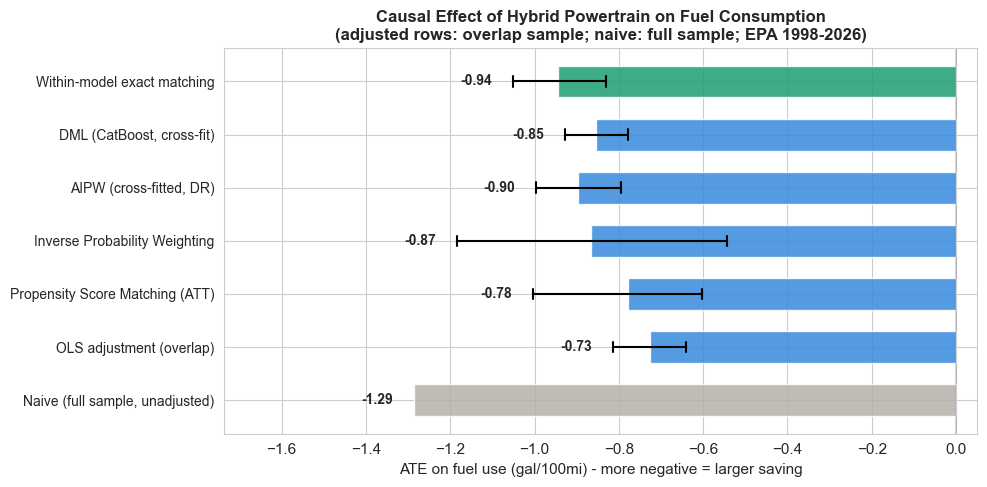

In [26]:
fig, ax = plt.subplots(figsize=(10, 5))
y_pos = range(len(results))
colors = [GREY] + [BLUE] * 5 + [GREEN]
ax.barh(y_pos, results['ATE_gp100'], color=colors, edgecolor='white', alpha=0.85, height=0.6)
for i, r in results.iterrows():
    if pd.notna(r['CI_low']):
        ax.plot([r['CI_low'], r['CI_high']], [i, i], color='black', linewidth=1.5, zorder=5)
        ax.plot([r['CI_low']]*2, [i-0.1, i+0.1], color='black', linewidth=1.5)
        ax.plot([r['CI_high']]*2, [i-0.1, i+0.1], color='black', linewidth=1.5)
    lab_x = (r['CI_low'] if pd.notna(r['CI_low']) else r['ATE_gp100']) - 0.05
    ax.text(lab_x, i, f"{r['ATE_gp100']:+.2f}", va='center', ha='right',
            fontsize=10, fontweight='bold')
ax.set_xlim(min(results['ATE_gp100'].min(), results['CI_low'].min()) - 0.45, 0.05)
ax.set_yticks(y_pos)
ax.set_yticklabels(results['Estimator'], fontsize=10)
ax.set_xlabel('ATE on fuel use (gal/100mi) - more negative = larger saving', fontsize=11)
ax.set_title('Causal Effect of Hybrid Powertrain on Fuel Consumption\n'
             f'(adjusted rows: overlap sample; naive: full sample; EPA {YR})',
             fontsize=12, fontweight='bold')
ax.axvline(0, color='gray', alpha=0.3)
plt.tight_layout()
plt.savefig('05_estimator_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## 15. Sensitivity analysis: Rosenbaum bounds

How strong would an unobserved confounder need to be to explain away the result?
Applied to the within-model matched pairs (per-nameplate fuel saving).

In [27]:
from scipy import stats


def rosenbaum_bounds(diff, gammas):
    """Wilcoxon signed-rank based Rosenbaum bounds (diff > 0 = hybrid saves fuel).
    Zero differences are dropped before ranking (standard signed-rank convention)."""
    diff = diff[diff != 0]
    ranks = stats.rankdata(np.abs(diff))
    T_obs = np.sum(ranks[diff > 0])
    out = []
    for gamma in gammas:
        p_plus = gamma / (1 + gamma)
        E_T = np.sum(ranks * p_plus)
        Var_T = np.sum(ranks ** 2 * p_plus * (1 - p_plus))
        z = (T_obs - E_T) / np.sqrt(Var_T) if Var_T > 0 else 0
        out.append({'Gamma': gamma, 'p_upper': 1 - stats.norm.cdf(z)})
    return pd.DataFrame(out)


# Collapse to one mean fuel saving per nameplate: the matched pairs are not
# independent (the same platform recurs across years/drivetrains), so treating them
# as independent overstates the evidence. Saving > 0 means the hybrid uses less fuel.
saving = -pairs_df.groupby('cluster_key')['gp_diff'].mean().values
if len(saving) > 5:
    gammas = [1.0, 1.5, 2.0, 2.5, 3.0, 4.0, 5.0, 6.0, 8.0, 10.0]
    bounds = rosenbaum_bounds(saving, gammas)
    print(f"Rosenbaum Sensitivity Analysis (within-model, {len(saving)} nameplates):")
    print("  Gamma = odds ratio of unmeasured confounding\n")
    for _, r in bounds.iterrows():
        sig = "***" if r['p_upper'] < 0.001 else "**" if r['p_upper'] < 0.01 else \
              "*" if r['p_upper'] < 0.05 else "ns"
        print(f"  Gamma={r['Gamma']:5.1f}:  p_upper={r['p_upper']:.4f}  {sig}")
    crit = bounds.loc[bounds['p_upper'] > 0.05, 'Gamma']
    if len(crit) > 0:
        print(f"\n  Result robust to unmeasured confounding up to Gamma={crit.iloc[0]:.1f}")
    else:
        print(f"\n  Result robust even at Gamma={gammas[-1]:.1f} - very strong finding")

Rosenbaum Sensitivity Analysis (within-model, 142 nameplates):
  Gamma = odds ratio of unmeasured confounding

  Gamma=  1.0:  p_upper=0.0000  ***
  Gamma=  1.5:  p_upper=0.0000  ***
  Gamma=  2.0:  p_upper=0.0000  ***
  Gamma=  2.5:  p_upper=0.0000  ***
  Gamma=  3.0:  p_upper=0.0000  ***
  Gamma=  4.0:  p_upper=0.0000  ***
  Gamma=  5.0:  p_upper=0.0001  ***
  Gamma=  6.0:  p_upper=0.0006  ***
  Gamma=  8.0:  p_upper=0.0043  **
  Gamma= 10.0:  p_upper=0.0140  *

  Result robust even at Gamma=10.0 - very strong finding


## 16. Improvement 1/8 - Alternative outcome scales (fuel, CO2)

gal/100mi is the right *scale*, but decision-makers think in L/100km, annual fuel,
and annual CO2. We translate the DML effect into those units and re-estimate the
effect directly on tailpipe CO2 (g/mi) as a policy-relevant secondary outcome.

In [28]:
GAL_TO_L = 3.785411784
MI_TO_KM = 1.609344
MI_PER_YR = 15000
KG_CO2_PER_GAL = 8.887  # EPA, gasoline

l_per_100km = ate_dml * GAL_TO_L / MI_TO_KM          # gal/100mi -> L/100km
ann_gal = ate_dml / 100 * MI_PER_YR                  # annual gallons at 15k mi/yr
ann_co2_fuel = ann_gal * KG_CO2_PER_GAL              # annual CO2 (kg) implied by fuel

# Direct DML on tailpipe CO2 (g/mi) over the overlap sample
co2_all = df_clean['co2TailpipeGpm'].values.astype(float)
ate_co2, se_co2 = dml_estimate(Xd_ov, T_ov.astype(float), co2_all[ov], clu_ov)

print("Hybrid effect expressed on multiple scales (DML point estimate):")
print(f"  Fuel:  {ate_dml:+.2f} gal/100mi  =  {l_per_100km:+.2f} L/100km")
print(f"  Annual fuel (15k mi/yr): {ann_gal:+.0f} gallons/year")
print(f"  Annual CO2 (via fuel):   {ann_co2_fuel:+.0f} kg/year")
print(f"  Direct DML on tailpipe CO2: {ate_co2:+.1f} g/mi "
      f"(={ate_co2*MI_PER_YR/1000:+.0f} kg/year, SE={se_co2:.1f})")

Hybrid effect expressed on multiple scales (DML point estimate):
  Fuel:  -0.85 gal/100mi  =  -2.01 L/100km
  Annual fuel (15k mi/yr): -128 gallons/year
  Annual CO2 (via fuel):   -1137 kg/year
  Direct DML on tailpipe CO2: -76.9 g/mi (=-1153 kg/year, SE=3.3)


## 17. Improvement 2/8 - Flexible functional form for the OLS baseline

The linear-in-year, linear-in-displacement OLS is a strong assumption. We refit
with **year as fixed effects** and quadratic displacement/cylinders. If the ATE is
stable, the linear baseline was not driving the result.

In [29]:
ov_df = df_clean.loc[ov].reset_index(drop=True)
flex = pd.concat([
    pd.DataFrame({'displ': ov_df['displ'], 'displ2': ov_df['displ'] ** 2,
                  'cyl': ov_df['cylinders'], 'cyl2': ov_df['cylinders'] ** 2,
                  'turbo': ov_df['turbo']}),
    pd.get_dummies(ov_df['year'].astype(int), prefix='yr', drop_first=True).astype(float),
    pd.get_dummies(ov_df[cat_cov], drop_first=True).astype(float),
], axis=1)
X_flex = sm.add_constant(np.column_stack([T_ov.astype(float), flex.values]))
ols_flex = sm.OLS(Y_ov, X_flex).fit(cov_type='cluster', cov_kwds={'groups': clu_ov})
ci_flex = ols_flex.conf_int()[1]
print("Flexible OLS (year fixed effects + quadratic displ/cyl, cluster-robust):")
print(f"  ATE: {ols_flex.params[1]:+.3f} gal/100mi   95% CI: [{ci_flex[0]:.3f}, {ci_flex[1]:.3f}]")
print(f"  (linear-form OLS was {ate_ols:+.3f}) -> effect is {'stable' if abs(ols_flex.params[1]-ate_ols)<0.15 else 'sensitive'}")

Flexible OLS (year fixed effects + quadratic displ/cyl, cluster-robust):
  ATE: -0.786 gal/100mi   95% CI: [-0.861, -0.711]
  (linear-form OLS was -0.726) -> effect is stable


## 18. Improvement 3/8 - Caliper + Mahalanobis matching with a Love plot

The 1:1 PS match had no caliper and only checked PS balance. We add a caliper on
the PS logit (0.2 x SD, Austin 2011) and match on the **Mahalanobis distance of the
raw covariates**, then check balance on every covariate with a Love plot.

Mahalanobis + caliper matching: 264/1763 hybrids matched (caliper=0.301 on PS logit)
  Feasible-subset ATT: -0.764 gal/100mi (-15.3% fuel)
  95% cluster-bootstrap CI (re-matched): [-1.003, -0.609]


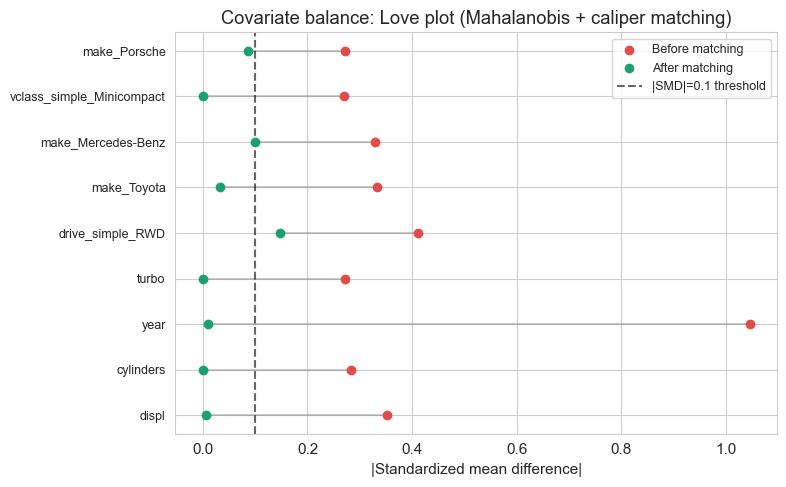

  Mean |SMD|: before=0.396 -> after=0.043


In [30]:
covs = ov_df[['displ', 'cylinders', 'year', 'turbo']].values.astype(float)
VI = np.linalg.inv(np.cov(covs.T))
# Whiten so plain Euclidean NN equals Mahalanobis distance (VI = L L^T). This lets
# the matcher use a fast KD-tree - important for re-matching inside the bootstrap.
L = np.linalg.cholesky(VI)
with np.errstate(all='ignore'):   # silence a spurious Accelerate-BLAS matmul FP warning
    covs_w = covs @ L
logit_ps = np.log(np.clip(ps_ov, 1e-6, 1 - 1e-6) / (1 - np.clip(ps_ov, 1e-6, 1 - 1e-6)))
caliper = 0.2 * logit_ps.std()

it = np.where(T_ov == 1)[0]
ic = np.where(T_ov == 0)[0]
_, idxm = NearestNeighbors(n_neighbors=1).fit(covs_w[ic]).kneighbors(covs_w[it])
cand = ic[idxm.ravel()]
within_caliper = np.abs(logit_ps[it] - logit_ps[cand]) <= caliper
it_ok, cand_ok = it[within_caliper], cand[within_caliper]

ate_maha = Y_ov[it_ok].mean() - Y_ov[cand_ok].mean()


def maha_att(rows):
    """Mahalanobis+caliper matching on a set of overlap rows -> ATT of the
    caliper-feasible subset. Re-matches per call for an honest bootstrap CI."""
    t, y, c, lp = T_ov[rows], Y_ov[rows], covs_w[rows], logit_ps[rows]
    it_, ic_ = np.where(t == 1)[0], np.where(t == 0)[0]
    if len(it_) == 0 or len(ic_) == 0:
        return None
    _, ix = NearestNeighbors(n_neighbors=1).fit(c[ic_]).kneighbors(c[it_])
    cnd = ic_[ix.ravel()]
    ok = np.abs(lp[it_] - lp[cnd]) <= caliper
    return (y[it_[ok]].mean() - y[cnd[ok]].mean()) if ok.sum() else None


ci_maha = cluster_boot_ci(clu_ov, maha_att)[:2]
print(f"Mahalanobis + caliper matching: {within_caliper.sum()}/{len(it)} hybrids matched "
      f"(caliper={caliper:.3f} on PS logit)")
print(f"  Feasible-subset ATT: {ate_maha:+.3f} gal/100mi ({ate_maha/gas_base_ov*100:+.1f}% fuel)")
print(f"  95% cluster-bootstrap CI (re-matched): [{ci_maha[0]:.3f}, {ci_maha[1]:.3f}]")

# Balance before vs after (SMD), continuous + top imbalanced dummies
bal_cols = ['displ', 'cylinders', 'year', 'turbo'] + [c for c, _ in cat_smds[:5]]
ov_dummies = pd.get_dummies(ov_df[cat_cov], drop_first=True).astype(float)
ov_full = pd.concat([ov_df[['displ', 'cylinders', 'year', 'turbo']], ov_dummies], axis=1)
smd_before, smd_after = [], []
for c in bal_cols:
    v = ov_full[c].values
    smd_before.append(abs(smd(pd.Series(v[it]), pd.Series(v[ic]))))
    smd_after.append(abs(smd(pd.Series(v[it_ok]), pd.Series(v[cand_ok]))))

fig, ax = plt.subplots(figsize=(8, 5))
yp = np.arange(len(bal_cols))
ax.scatter(smd_before, yp, color=RED, label='Before matching', zorder=3)
ax.scatter(smd_after, yp, color=GREEN, label='After matching', zorder=3)
for i in yp:
    ax.plot([smd_after[i], smd_before[i]], [i, i], color='gray', alpha=0.4, zorder=1)
ax.axvline(0.1, color='black', linestyle='--', alpha=0.6, label='|SMD|=0.1 threshold')
ax.set_yticks(yp)
ax.set_yticklabels(bal_cols, fontsize=9)
ax.set_xlabel('|Standardized mean difference|')
ax.set_title('Covariate balance: Love plot (Mahalanobis + caliper matching)')
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig('06_love_plot.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"  Mean |SMD|: before={np.mean(smd_before):.3f} -> after={np.mean(smd_after):.3f}")

## 19. Improvement 4/8 - Overlap weights (ATO)

Instead of a hard common-support cut plus IPW (which produced the outlying IPW
estimate), overlap weights (Li, Morgan & Zaslavsky 2018) apply *data-driven*
continuous down-weighting of non-overlapping units. Weights: w = (1-e) for
treated, e for control. The estimand is the effect in the overlap population (ATO),
with exact mean balance and no tuning. Computed on the **full** sample.

In [31]:
def ato_estimate(rows):
    t, y, e = T[rows], Y[rows], np.clip(ps[rows], 1e-6, 1 - 1e-6)
    w = np.where(t == 1, 1 - e, e)
    num1, den1 = (w * t * y).sum(), (w * t).sum()
    num0, den0 = (w * (1 - t) * y).sum(), (w * (1 - t)).sum()
    if den1 == 0 or den0 == 0:
        return None
    return num1 / den1 - num0 / den0


ate_ato = ato_estimate(np.arange(len(Y)))
ci_ato = cluster_boot_ci(cluster_id, ato_estimate)[:2]
print("Overlap weights (ATO, full sample):")
print(f"  ATE: {ate_ato:+.3f} gal/100mi ({ate_ato/Y[T==0].mean()*100:+.1f}% fuel)")
print(f"  95% cluster-bootstrap CI: [{ci_ato[0]:.3f}, {ci_ato[1]:.3f}]")

Overlap weights (ATO, full sample):
  ATE: -0.893 gal/100mi (-17.7% fuel)
  95% cluster-bootstrap CI: [-1.087, -0.686]


## 20. Improvement 5/8 - Library estimators (DoubleML IRM, EconML Causal Forest)

Replace the hand-rolled AIPW/DML with battle-tested implementations that carry
Neyman-orthogonal scores, proper cross-fitting and analytic inference: DoubleML's
interactive regression model (IRM, doubly-robust ATE, made cluster-robust here)
and EconML's CausalForestDML (heterogeneous effects; its CI is row-level, not
cluster-robust, so read it as approximate).

In [32]:
from doubleml import DoubleMLClusterData, DoubleMLIRM
from econml.dml import CausalForestDML

# Cluster-robust DoubleML: pass nameplate clusters so the IRM CI accounts for the
# same non-independence as the hand estimators; seed the fold splits (IRM draws
# from the global RNG and is otherwise nondeterministic).
np.random.seed(42)
dml_data = DoubleMLClusterData.from_arrays(Xd_ov, Y_ov, T_ov, cluster_vars=clu_ov.reshape(-1, 1))
irm = DoubleMLIRM(dml_data, ml_g=cb_reg(), ml_m=cb_clf(), n_folds=5)
irm.fit()
ci_irm = irm.confint().values.ravel()
print("DoubleML IRM (doubly-robust ATE, CatBoost nuisances, cluster-robust):")
print(f"  ATE: {irm.coef[0]:+.3f} gal/100mi   95% CI: [{ci_irm[0]:.3f}, {ci_irm[1]:.3f}]")

cf = CausalForestDML(
    model_y=cb_reg(), model_t=cb_clf(),
    discrete_treatment=True, cv=GroupKFold(n_splits=3), n_estimators=300,
    min_samples_leaf=10, n_jobs=1, random_state=42)
cf.fit(Y_ov, T_ov, X=Xd_ov, groups=clu_ov)
ate_cf = cf.ate(Xd_ov)
ci_cf = cf.ate_interval(Xd_ov)
print("EconML CausalForestDML (heterogeneous, library):")
print(f"  ATE: {ate_cf:+.3f} gal/100mi   95% CI: [{ci_cf[0]:.3f}, {ci_cf[1]:.3f}]")
print("  (row-level CI, wide under low treatment prevalence; use the point estimate)")

DoubleML IRM (doubly-robust ATE, CatBoost nuisances, cluster-robust):
  ATE: -0.879 gal/100mi   95% CI: [-0.959, -0.799]


EconML CausalForestDML (heterogeneous, library):
  ATE: -1.425 gal/100mi   95% CI: [-7.674, 4.825]
  (row-level CI, wide under low treatment prevalence; use the point estimate)


## 21. Improvement 6/8 - Refutation / falsification tests

Following the DoWhy refutation framework, we stress-test the design with a fast
partial-linear DML estimator:
- **Placebo treatment**: permute the treatment - a real design should give ~0.
- **Random common cause**: add an irrelevant covariate - estimate should not move.
- **Data subset**: re-estimate on random subsamples - estimate should be stable.
- **Negative-control outcome**: hybridness should not affect passenger volume.

In [33]:
def fast_dml(X, T, Y, groups, seed=42):
    """Partial-linear DML with CatBoost nuisances (light config, for stress tests);
    GroupKFold so replicate trims do not leak across folds."""
    rY, rT = np.zeros(len(Y)), np.zeros(len(T))
    gkf = GroupKFold(n_splits=5, shuffle=True, random_state=seed)
    for tr, te in gkf.split(X, groups=groups):
        my = cb_reg(seed, iters=150).fit(X[tr], Y[tr])
        mt = cb_reg(seed, iters=150).fit(X[tr], T[tr])
        rY[te] = Y[te] - my.predict(X[te])
        rT[te] = T[te] - mt.predict(X[te])
    return np.sum(rT * rY) / np.sum(rT ** 2)


real_theta = fast_dml(Xd_ov, T_ov.astype(float), Y_ov, clu_ov)

rng = np.random.RandomState(0)
placebo = np.array([fast_dml(Xd_ov, rng.permutation(T_ov).astype(float), Y_ov, clu_ov, seed=s)
                    for s in range(8)])

Xd_rcc = np.column_stack([Xd_ov, rng.normal(size=len(Y_ov))])
theta_rcc = fast_dml(Xd_rcc, T_ov.astype(float), Y_ov, clu_ov)

subset = []
for s in range(6):
    idx = rng.choice(len(Y_ov), size=int(0.8 * len(Y_ov)), replace=False)
    subset.append(fast_dml(Xd_ov[idx], T_ov[idx].astype(float), Y_ov[idx], clu_ov[idx], seed=s))
subset = np.array(subset)

# Negative-control outcome: passenger volume, where recorded. Powertrain should have
# little effect on interior packaging, so a cluster-robust DML effect near zero
# supports the design. Caveat: pv4>0 conditions on 4-door body styles, and battery
# placement can shrink cabin space, so a small nonzero effect is not disqualifying.
pv4 = df_clean['pv4'].values.astype(float)
nco_mask = ov & (pv4 > 0)
theta_nco, se_nco = dml_estimate(Xd[nco_mask], T[nco_mask].astype(float),
                                 pv4[nco_mask], cluster_id[nco_mask])
z_nco = theta_nco / se_nco
d_main = abs(real_theta) / Y_ov.std()
d_nco = abs(theta_nco) / pv4[nco_mask].std()

print("Refutation / falsification tests:")
print(f"  Real effect (fast DML):  {real_theta:+.3f} gal/100mi")
print(f"  Placebo treatment:       {placebo.mean():+.3f} +/- {placebo.std():.3f}  "
      f"(should be ~0; |real| beyond placebo range: {abs(real_theta) > np.abs(placebo).max()})")
print(f"  Random common cause:     {theta_rcc:+.3f}  (should ~= real)")
print(f"  Data subset (80%):       {subset.mean():+.3f} +/- {subset.std():.3f}  (should ~= real)")
print(f"  Negative-control (pv4):  effect={theta_nco:+.2f} cu ft (SE {se_nco:.2f}, z={z_nco:+.1f}); "
      f"standardized {d_nco:.2f} vs main {d_main:.2f}")

Refutation / falsification tests:
  Real effect (fast DML):  -0.864 gal/100mi
  Placebo treatment:       -0.010 +/- 0.009  (should be ~0; |real| beyond placebo range: True)
  Random common cause:     -0.863  (should ~= real)
  Data subset (80%):       -0.864 +/- 0.013  (should ~= real)
  Negative-control (pv4):  effect=+1.30 cu ft (SE 0.43, z=+3.0); standardized 0.15 vs main 0.72


## 22. Improvement 7/8 - E-value sensitivity (VanderWeele & Ding)

The E-value is the minimum strength of association (on the risk-ratio scale) that
an unmeasured confounder would need with *both* treatment and outcome to explain
away the effect. For a continuous outcome we map the standardized effect to an
approximate RR (RR ~= exp(0.91 x d)).

In [34]:
def e_value(d):
    rr = np.exp(0.91 * abs(d))
    return rr + np.sqrt(rr * (rr - 1))


sd_y = Y_ov.std()
d_point = ate_dml / sd_y
ci_near_null = ci_dml[1]           # both bounds negative; the one nearest 0
d_ci = ci_near_null / sd_y
print("E-value sensitivity (primary DML estimate):")
print(f"  Standardized effect d = {d_point:.3f}  ->  E-value (point) = {e_value(d_point):.2f}")
print(f"  For the CI bound nearest null ({ci_near_null:+.2f}) -> E-value = {e_value(d_ci):.2f}")
print(f"  Interpretation: an unmeasured confounder would need RR ~ {e_value(d_point):.1f}"
      f" with both hybrid-status and fuel use to explain away the effect.")

E-value sensitivity (primary DML estimate):
  Standardized effect d = -0.706  ->  E-value (point) = 3.21
  For the CI bound nearest null (-0.78) -> E-value = 2.99
  Interpretation: an unmeasured confounder would need RR ~ 3.2 with both hybrid-status and fuel use to explain away the effect.


## 23. Improvement 8/8 - Rated vs real-world caveat

All estimates use EPA **rated** fuel economy. Real-world tests show hybrids fall
short of their EPA label by ~10% vs ~2% for conventional cars (Consumer Reports),
because EPA cycles favor the conditions where hybrids excel. So the real-world
advantage is somewhat smaller. Illustrative bracket applied to the within-model
pairs (hybrid +10% fuel, gasoline +2% fuel in the real world):

In [35]:
rw_hyb = pairs_df['gp_hybrid'] * 1.10
rw_gas = pairs_df['gp_gas'] * 1.02
rw_diff = (rw_hyb - rw_gas).mean()
rw_pct = ((rw_hyb - rw_gas) / rw_gas * 100).mean()
print("Rated vs real-world (illustrative, within-model pairs):")
print(f"  Rated:      {pairs_df['gp_diff'].mean():+.3f} gal/100mi ({pairs_df['gp_pct'].mean():+.1f}% fuel)")
print(f"  Real-world: {rw_diff:+.3f} gal/100mi ({rw_pct:+.1f}% fuel)  <- ~10%/2% shortfall applied")
print("  The sign and rough magnitude survive; the point estimate shrinks modestly.")

Rated vs real-world (illustrative, within-model pairs):
  Rated:      -0.944 gal/100mi (-22.9% fuel)
  Real-world: -0.699 gal/100mi (-16.8% fuel)  <- ~10%/2% shortfall applied
  The sign and rough magnitude survive; the point estimate shrinks modestly.


## 24. Extended estimator comparison (with improvements)

In [36]:
ext = results.copy()
# Mahalanobis+caliper (section 18) matches only a caliper-feasible subset (~15% of
# hybrids) -> too small for a headline comparison; it stays in its own section as a
# balance diagnostic, not here.
extra = pd.DataFrame({
    'Estimator': ['Overlap weights (ATO)', 'DoubleML IRM (library)', 'Causal Forest (EconML)'],
    'ATE_gp100': [ate_ato, irm.coef[0], ate_cf],
    'CI_low': [ci_ato[0], ci_irm[0], ci_cf[0]],
    'CI_high': [ci_ato[1], ci_irm[1], ci_cf[1]],
})
# ATO is a full-sample estimand -> full-sample baseline; the rest are overlap.
extra['pct_fuel'] = extra['ATE_gp100'] / np.array([base_full, gas_base_ov, gas_base_ov]) * 100
ext = pd.concat([ext, extra], ignore_index=True)

print("=" * 84)
print("  EXTENDED COMPARISON: original + improvement estimators (gal/100mi)")
print("=" * 84)
for _, r in ext.iterrows():
    ci = f"[{r['CI_low']:+.2f}, {r['CI_high']:+.2f}]" if pd.notna(r['CI_low']) else "N/A"
    print(f"  {r['Estimator']:34s} ATE = {r['ATE_gp100']:+.2f}  ({r['pct_fuel']:+5.1f}% fuel)  95% CI: {ci}")
print("=" * 84)

  EXTENDED COMPARISON: original + improvement estimators (gal/100mi)
  Naive (full sample, unadjusted)    ATE = -1.29  (-25.5% fuel)  95% CI: N/A
  OLS adjustment (overlap)           ATE = -0.73  (-14.5% fuel)  95% CI: [-0.81, -0.64]
  Propensity Score Matching (ATT)    ATE = -0.78  (-15.6% fuel)  95% CI: [-1.00, -0.60]
  Inverse Probability Weighting      ATE = -0.87  (-17.3% fuel)  95% CI: [-1.18, -0.54]
  AIPW (cross-fitted, DR)            ATE = -0.90  (-17.9% fuel)  95% CI: [-1.00, -0.79]
  DML (CatBoost, cross-fit)          ATE = -0.85  (-17.1% fuel)  95% CI: [-0.93, -0.78]
  Within-model exact matching        ATE = -0.94  (-22.3% fuel)  95% CI: [-1.05, -0.83]
  Overlap weights (ATO)              ATE = -0.89  (-17.7% fuel)  95% CI: [-1.09, -0.69]
  DoubleML IRM (library)             ATE = -0.88  (-17.6% fuel)  95% CI: [-0.96, -0.80]
  Causal Forest (EconML)             ATE = -1.42  (-28.5% fuel)  95% CI: [-7.67, +4.82]


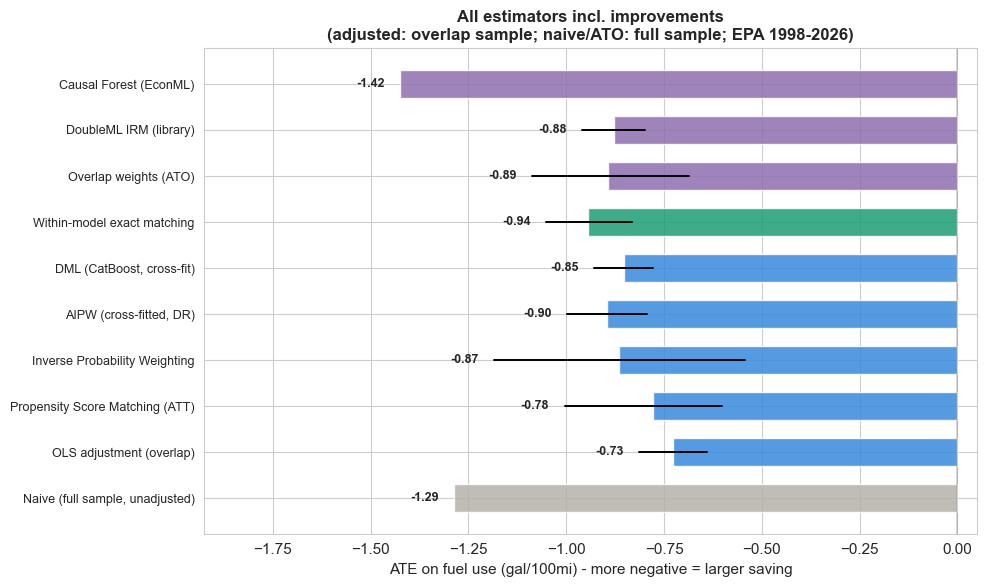

In [37]:
fig, ax = plt.subplots(figsize=(10, 6))
yp = range(len(ext))
colors = [GREY] + [BLUE] * 5 + [GREEN] + ['#8E6FB0'] * 3
ax.barh(yp, ext['ATE_gp100'], color=colors[:len(ext)], edgecolor='white', alpha=0.85, height=0.6)
# Draw a whisker only where the CI is finite and reasonably tight; the causal-forest
# ATE CI is very wide under rare treatment and would otherwise swamp the axis.
narrow = ext['CI_low'].notna() & ((ext['CI_high'] - ext['CI_low']).abs() < 3)
for i, r in ext.iterrows():
    if narrow[i]:
        ax.plot([r['CI_low'], r['CI_high']], [i, i], color='black', linewidth=1.4, zorder=5)
    lab_x = (r['CI_low'] if narrow[i] else r['ATE_gp100']) - 0.04
    ax.text(lab_x, i, f"{r['ATE_gp100']:+.2f}", va='center', ha='right',
            fontsize=9, fontweight='bold')
ax.set_xlim(min(ext['ATE_gp100'].min(), ext.loc[narrow, 'CI_low'].min()) - 0.5, 0.05)
ax.set_yticks(list(yp))
ax.set_yticklabels(ext['Estimator'], fontsize=9)
ax.set_xlabel('ATE on fuel use (gal/100mi) - more negative = larger saving')
ax.set_title('All estimators incl. improvements\n'
             f'(adjusted: overlap sample; naive/ATO: full sample; EPA {YR})',
             fontsize=12, fontweight='bold')
ax.axvline(0, color='gray', alpha=0.3)
plt.tight_layout()
plt.savefig('07_extended_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## Key takeaways

1. **Measure fuel, not MPG.** In MPG the naive gap is ~+9 MPG (~+42%), which sounds
   large, but MPG is the reciprocal of consumption. In gallons/100mi the same data
   show hybrids use ~26% less fuel - the honest quantity for savings/CO2.

2. **Adjustment matters, but less than the metric.** Confounder adjustment pulls the
   naive gap down to a smaller, credible effect. The adjusted estimators cluster
   near -0.85 to -0.90 gal/100mi (~-17-18%; doubly-robust AIPW/DML/IRM/ATO), with
   OLS/PSM a little lower (-0.73/-0.78) and within-model a little higher (-0.94) -
   all far below the naive.

3. **The estimand is the overlap effect, not a whole-fleet ATE.** Hybrids and
   gasoline vehicles overlap only in part of the covariate space (big pickups have
   no hybrid counterpart), so a population ATE is not identified. We restrict to
   common support; matching rows target the ATT.

4. **Honest uncertainty.** Observations are clustered by nameplate, nuisance models
   are cross-fitted with GroupKFold, and the library IRM uses cluster-robust
   inference, so confidence intervals reflect the real effective sample size, not
   the inflated row count.

5. **Heterogeneity.** On the overlap sample (off-support bins excluded), city
   savings are roughly 3x highway (~-1.4 vs -0.4 gal/100mi), consistent with
   regenerative braking and engine-off idling paying off most in stop-and-go use.
   The per-distance saving varies by segment - smallest for two-seaters (mostly
   mild-hybrid sports cars) and larger for big, high-displacement vehicles.

6. **Within-model matching** (same nameplate and drive, gas vs hybrid) is the
   cleanest design and corroborates the model-based estimators; Rosenbaum bounds
   (per-nameplate) show the sign is robust to substantial unmeasured confounding.

7. **Effect depends on the data vintage.** On this 1984-2026 snapshot the adjusted
   effect is ~-0.75 to -1.0 gal/100mi (doubly-robust ~-0.85 to -0.90); on an older
   MY2015 snapshot it was larger (~-1.1 to -1.2). Two reasons: (a) the modern fleet
   is more fuel-efficient overall, so absolute gaps shrink, and (b) EPA's "Hybrid"
   class now mixes full HEVs with 48V mild hybrids, which save far less fuel and
   dilute the treatment. Splitting full vs mild hybrids (via eng_dscr / evMotor) is
   left as future work.